# 03b — Taxa manual da carteira

O mesmo fluxo do 03a (framework da SOA e monografia nº 5 da CAS), agora na carteira contra a BR-EMSmt 2026, com
**partição fora do tempo** como faz a SOA: treino com a experiência até 2023, teste em 2024.

$$
N_c \sim \text{Poisson}(\mu_c), \qquad \log \mu_c = \log E_c + \beta_0 + \beta_{cap}\,\log\frac{\text{capital}_c}{\text{ref}} + \beta_{\text{seção}(c)} + \dots
$$

| Candidato | Papel | Origem |
|---|---|---|
| Plano atual (tábua × A/E) | o que se compara | CAS 4.3.3 |
| GLM (capital e seção) | candidato a tarifa | SOA 4.1 |
| GLMM (+ efeito de divisão e de estipulante) | candidato a tarifa | adaptação: CAS 10.1 e evidência do 03a (grupos têm mortalidade própria) |
| Ridge com priori SOA | candidato a tarifa | adaptação: priori do estudo de mercado via penalização (SOA 4.3.1) |
| Elastic net (LASSO) + interações do LightGBM | referência de desempenho | SOA 4.3 |
| LightGBM | referência de desempenho | SOA 4.2 |

Elastic net com interações e LightGBM não viram tarifa: não cabem numa tabela de fatores explicável nem na nota
técnica. Se uma referência ganhar de todos os candidatos com significância, isso sinaliza estrutura faltando; a
interação mais forte apontada pelo LightGBM é testada diretamente no GLMM (seção 4).

**Anos excluídos da experiência:** os de choque externo identificado (`excluir_anos_experiencia`; hoje, 2021),
com a evidência no notebook 05.

**Regra de decisão** (fixada antes do teste, em `config/manual.yaml`): menor deviance no teste entre os candidatos a
tarifa; empates (IC de 95% da diferença, por bootstrap pareado **por estipulante**, contém zero) resolvidos pela
ordem de preferência. O escolhido é reajustado com toda a experiência maturada (CAS 4.3.3).

In [1]:
import sys, warnings
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
warnings.filterwarnings("ignore", message="Efeitos aleatórios com variância nula")   # informado explicitamente abaixo
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from vgpricing.config import carregar_config
from vgpricing.tabua import obter_tabua
from vgpricing import manual as M, glmm as G, elasticnet as EN, diagnostico as D, avaliacao as A, prioris as PR
from vgpricing.graficos import estilo
estilo()

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
cfg, cm, cmo = (carregar_config(n, RAIZ) for n in ("base", "manual", "modelagem"))
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message=".*coluna lx.*")
    tabua = obter_tabua(cfg, RAIZ)
assert not tabua.placeholder and G.r_disponivel(), "Precisa da tábua oficial e do R (veja o README)"
limpo = RAIZ / cfg["pasta_processados"] / "limpo"
dados = {t: pd.read_parquet(limpo / f"{t}.parquet") for t in ("estipulantes", "vidas", "sinistros")}
prioris = M.carregar_tabela(RAIZ / "artefatos/prioris_soa.yaml")               # gerado no 03a
FT = cm["fora_do_tempo"]
base = lambda janela: M.base_modelagem(dados["vidas"], dados["sinistros"], dados["estipulantes"], tabua,
                                       cfg["data_referencia"], cm, cfg["exposicao"]["dias_por_ano"], janela=janela,
                                       excluir_anos=tuple(cm["excluir_anos_experiencia"]))
tr, itr = base((None, FT["treino_ate"]))
te, ite = base(tuple(FT["teste"]))
secoes_treino = set(tr["cnae_secao"])
te["cnae_secao"] = te["cnae_secao_original"].where(te["cnae_secao_original"].isin(secoes_treino), "OUTRAS")
pd.DataFrame({"período": [f"até {itr['corte_experiencia']}", f"{ite['inicio_experiencia']} a {ite['corte_experiencia']}"],
              "óbitos": [itr["obitos"], ite["obitos"]], "esperados (tábua)": [itr["esperados"], ite["esperados"]],
              "estipulantes": [itr["estipulantes"], ite["estipulantes"]]}, index=["treino", "teste"])

,período,óbitos,esperados (tábua),estipulantes
treino,até 2023-12-31,2219,"2,116.5967",250
teste,2024-01-01 a 2024-12-31,553,554.3435,250


O teste usa o mapeamento de seções do treino (seções raras no treino viram "OUTRAS" nos dois).

## 1. GLM (SOA 4.1)

In [2]:
FIXOS = cm["modelo"]["fixos_obrigatorios"]
glm = M.ajustar_comparacao(tr, cm, FIXOS, "poisson")
an = G.ajustar_glmm(tr, FIXOS, [], categoricas=["cnae_secao"], numericas=["log_capital_c"],
                    niveis_base=M.niveis_base(tr, ["cnae_secao"]), anova=True).extra["anova"]
te["mu_glm"] = G.prever(glm, te)
print(f"Motor: {glm.extra['motor']} | dispersão de Pearson: {glm.extra['dispersao_pearson']:.3f}")
display(an)
glm.fixos.assign(fator=np.exp(glm.fixos["estimativa"]))

Motor: stats::glm | dispersão de Pearson: 1.391


,termo,gl,deviance,gl_residual,deviance_residual,p_valor
0,NULL,NaN,NaN,6938,"3,618.5444",NaN
1,log_capital_c,1.0000,6.2176,6937,"3,612.3268",0.0126
2,cnae_secao,9.0000,74.2978,6928,"3,538.0290",0.0000


,nome,estimativa,ep,fator
0,(Intercept),0.1124,0.0518,1.1190
1,log_capital_c,-0.0678,0.0245,0.9345
2,cnae_secaoF,0.1243,0.0840,1.1324
3,cnae_secaoG,-0.0464,0.0813,0.9547
4,cnae_secaoH,0.1584,0.0750,1.1716
5,cnae_secaoK,-0.3374,0.1434,0.7136
6,cnae_secaoM,-0.4291,0.0956,0.6511
7,cnae_secaoN,-0.0971,0.0792,0.9074
8,cnae_secaoO,-0.1960,0.0856,0.8220
9,cnae_secaoP,-0.3440,0.1107,0.7089


## 2. GLMM (adaptação: efeito de grupo)

O 03a mostrou, com dados reais, que grupos têm mortalidade própria além do que as variáveis explicam. Aqui o
estipulante é identificado, então entra como efeito aleatório; a divisão CNAE entra como efeito aleatório dentro da
seção (credibilidade de Ohlsson). Idade, sexo e porte são candidatos, testados por razão de verossimilhança com
correção de Holm.

In [3]:
glmm, _, testes = M.ajustar_taxa_manual(tr, cm)
te["mu_glmm"] = G.prever(glmm, te)
print("Fórmula:", glmm.formula)
print("Efeitos aleatórios retirados por variância nula (ajuste singular):", glmm.extra["aleatorios_removidos"] or "nenhum")
display(testes)
M.comparar_dispersao(tr, cm, glmm)

Fórmula: N ~ log_capital_c + cnae_secao + (1 | id_estipulante) + offset(log(E))
Efeitos aleatórios retirados por variância nula (ajuste singular): ['(1|cnae_secao:cnae_divisao)']


,termo,tipo,lr,gl,p_valor,p_holm,decisao
0,faixa_idade,fixo,6.5382,4,0.1624,0.3248,não entra
1,sexo,fixo,0.9228,1,0.3367,0.3367,não entra
2,faixa_tamanho,fixo,8.0671,3,0.0446,0.1339,não entra
3,(1|cnae_secao:cnae_divisao),aleatorio,0.0000,1,1.0000,NaN,estrutura (mantido)
4,(1|id_estipulante),aleatorio,101.9986,1,0.0000,NaN,estrutura (mantido)


,modelo,dispersão,loglik,parametros,AIC,dif_AIC_vs_melhor
0,GLM Poisson,nenhuma,"-3,148.3878",11,"6,318.7756",104.4035
1,Binomial Negativa (NB2),"por célula, independente","-3,136.5986",12,"6,297.1973",82.8252
2,GLMM (efeitos de divisão e estipulante),por grupo e por atividade,"-3,095.1860",12,"6,214.3721",0.0000


Com as log-verossimilhanças na mesma base (todas no mesmo pacote), o modelo com efeito de estipulante tem AIC menor
que a Binomial Negativa: a sobredispersão está no grupo, não na célula.

## 3. Ridge com priori SOA (adaptação)

A forma do estudo da SOA (elasticidade ao capital e fatores relativos de seção, 03a) entra no offset:

$$
\log \mu_c = \underbrace{\log E_c + \beta^{SOA}\log\tfrac{\text{capital}_c}{\text{ref}} + \log f^{SOA}_{\text{seção}(c)}}_{\text{offset}} + b_0 + \delta\,\log\tfrac{\text{capital}_c}{\text{ref}} + \gamma_{\text{seção}(c)} .
$$

A penalização ridge encolhe $\delta$ e $\gamma$ para zero, ou seja, para o estudo: é uma priori normal centrada na
SOA, e o lambda (validação cruzada por estipulante) faz o papel do k da credibilidade (SOA 4.3.1).

In [4]:
tr["fold"] = A.folds_por_grupo(tr["id_estipulante"], cm["validacao_cruzada"]["folds"], cm["validacao_cruzada"]["semente"]) + 1
for d in (tr, te):
    d["log_E"], d["off_priori"] = np.log(d["E"]), PR.offset_priori(d, prioris)
ridge = EN.ajustar_elastic_net(tr, {"teste": te}, ["log_capital_c", "cnae_secao"], ["cnae_secao"], ["log_capital_c"],
                               "off_priori", alpha=0.0, foldid="fold")
te["mu_ridge"] = ridge.previsoes["teste"]
pd.Series({"elasticidade SOA (priori)": prioris["elasticidade_capital"],
           "desvio estimado na carteira (δ)": ridge.coeficientes["log_capital_c"],
           "elasticidade final": prioris["elasticidade_capital"] + ridge.coeficientes["log_capital_c"],
           "elasticidade no GLM (sem priori)": glm.coef("log_capital_c"),
           "lambda (validação cruzada)": ridge.lambda_escolhido}).to_frame("valor")

,valor
elasticidade SOA (priori),-0.0986
desvio estimado na carteira (δ),0.0027
elasticidade final,-0.0960
elasticidade no GLM (sem priori),-0.0678
lambda (validação cruzada),2.9667


## 4. Referências de desempenho: LightGBM e elastic net com interações (SOA 4.2 e 4.3)

In [5]:
VL = ["cnae_secao", "faixa_idade", "sexo", "log_capital_c", "faixa_tamanho"]
CL = [v for v in VL if v != "log_capital_c"]
lg = D.ajustar_residual(tr.assign(mu_manual=tr["E"]), D.config_lightgbm(cmo, "lightgbm_carteira", VL, CL))
te["mu_lgbm"] = D.prever(lg, te.assign(mu_manual=te["E"]))
inter = D.tabela_interacoes(lg["modelo"])
TOP = inter["interacao"].head(cmo["elastic_net"]["interacoes_do_lightgbm"]).tolist()
cen = cmo["elastic_net"]
en = EN.ajustar_elastic_net(tr, {"teste": te}, VL + TOP, CL, ["log_capital_c"], "log_E", alpha=cen["alpha"],
                            foldid="fold", lambda_=cen["lambda"], semente=cen["semente"], padronizar=cen["padronizar"])
te["mu_en"] = en.previsoes["teste"]
print(f"LightGBM: {lg['rodadas']} rodadas | interações para o elastic net: {TOP} | "
      f"coeficientes não nulos: {int((en.coeficientes.drop('(Intercept)') != 0).sum())}")
inter.head(5)

LightGBM: 91 rodadas | interações para o elastic net: ['cnae_secao:log_capital_c', 'faixa_idade:log_capital_c', 'cnae_secao:faixa_tamanho'] | coeficientes não nulos: 7


,interacao,sumGain,sumCover,frequency,meanCover,meanGain
0,cnae_secao:log_capital_c,244.5220,157132,56,"2,805.9286",4.3665
1,faixa_idade:log_capital_c,88.1591,117153,38,"3,082.9737",2.3200
2,cnae_secao:faixa_tamanho,68.3980,38118,18,"2,117.6667",3.7999
3,cnae_secao:faixa_idade,26.3802,18497,9,"2,055.2222",2.9311
4,faixa_tamanho:log_capital_c,14.0836,9279,4,"2,319.7500",3.5209


**Onde o LightGBM vê estrutura** (média do |SHAP| e SHAP por nível, como na SOA 4.2.4), e o **fechamento do ciclo**:
a interação mais forte da tabela vira uma hipótese concreta, testada no próprio GLMM por razão de verossimilhança.
Uma hipótese dirigida tem muito mais poder que a busca às cegas do LightGBM (o notebook 90 mede isso).

,média |SHAP|
cnae_secao,0.0641
log_capital_c,0.0309
faixa_idade,0.0082
faixa_tamanho,0.0048
sexo,0.0000


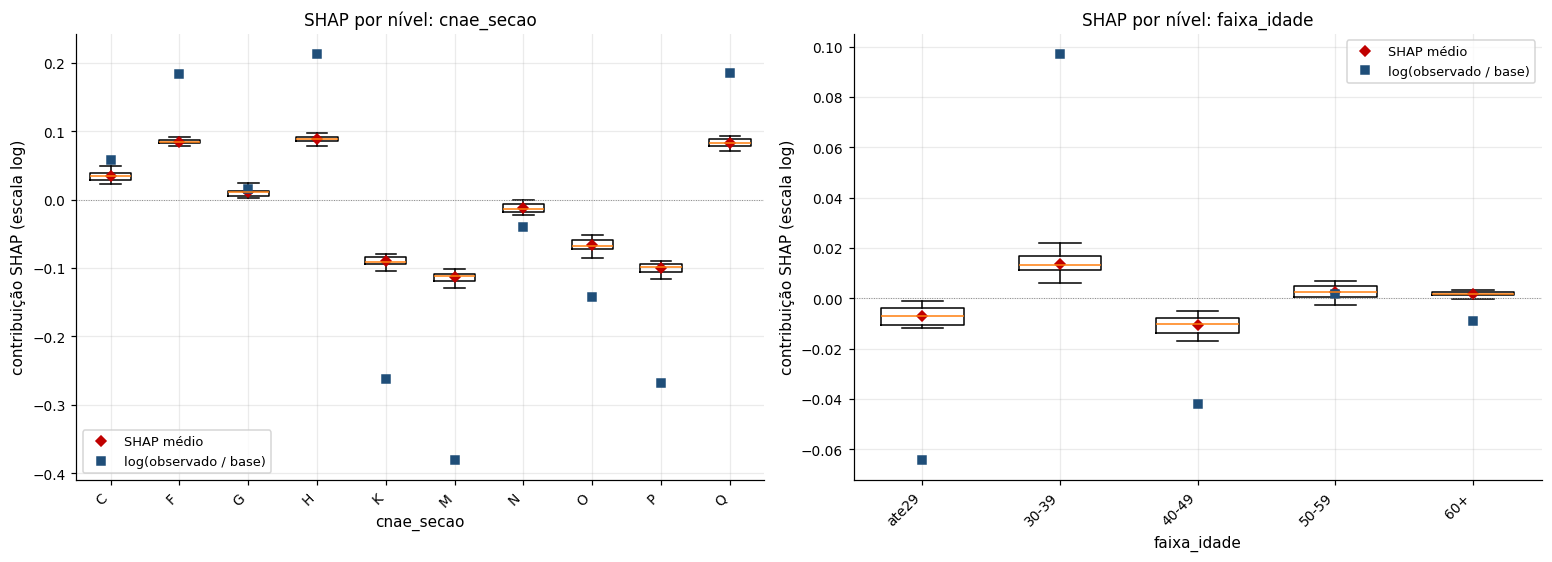

In [6]:
Xs = D._matriz(tr, VL, CL, lg["niveis"])
contrib = D.contribuicoes(lg["modelo"], Xs)
display(D.importancia(contrib, tr["E"].to_numpy()).to_frame("média |SHAP|"))
fig, axs = plt.subplots(1, 2, figsize=(14, 5))
for ax, v, ordem in zip(axs, ["cnae_secao", "faixa_idade"], [None, cm["faixas"]["idade"]["rotulos"]]):
    D.grafico_shap(ax, contrib, tr.assign(mu_manual=tr["E"]), v, ordem=ordem)
plt.show()

In [7]:
a, b = TOP[0].split(":")
categ = [x for x in (a, b) if x in CL]
teste_dirigido = D.testar_candidato_glmm(tr, cm, FIXOS, [TOP[0]], categoricas_extras=[c for c in categ if c != "cnae_secao"])
print(f"Interação testada no GLMM: {TOP[0]}")
teste_dirigido[["termo", "lr", "gl", "p_valor"]]

Interação testada no GLMM: cnae_secao:log_capital_c


,termo,lr,gl,p_valor
0,cnae_secao:log_capital_c,16.6240,9,0.0549


Se o p-valor não for pequeno, a interação apontada pelo LightGBM não se sustenta como fator de tarifa nesta carteira,
e a taxa manual fica com os efeitos principais. Se for, ela entra como candidata, com a mesma regra de decisão.

## 5. Comparação no teste (2024)

In [8]:
te["mu_plano"] = te["E"] * tr["N"].sum() / tr["E"].sum()
PREV = {"plano atual (tábua × A/E)": "mu_plano", "GLM": "mu_glm", "GLMM": "mu_glmm", "ridge com priori SOA": "mu_ridge",
        "elastic net + interações": "mu_en", "LightGBM": "mu_lgbm"}
m = A.metricas(te, PREV)
m["Gini"] = [A.lorenz_gini(te, c)[1] for c in PREV.values()]
m["papel"] = ["tarifa" if n in cm["decisao"]["ordem_preferencia"] else "referência" for n in PREV]
m

,modelo,deviance,MSE,MAE,A/M total,deviance vs melhor,Gini,papel
0,plano atual (tábua × A/E),"1,766.4939",0.0997,0.1172,0.9515,29.7317,-0.0435,tarifa
1,GLM,"1,736.7622",0.0962,0.1146,0.9516,0.0000,0.1323,tarifa
2,GLMM,"1,746.3479",0.0971,0.1158,0.9398,9.5857,0.1129,tarifa
3,ridge com priori SOA,"1,749.6414",0.0977,0.1152,0.9511,12.8792,0.0993,tarifa
4,elastic net + interações,"1,750.2412",0.0981,0.1165,0.9542,13.4790,0.0898,referência
5,LightGBM,"1,747.1997",0.0977,0.1153,0.9711,10.4375,0.1408,referência


In [9]:
TARIFA = {n: c for n, c in PREV.items() if n in cm["decisao"]["ordem_preferencia"]}
melhor = m[m["papel"] == "tarifa"].sort_values("deviance").iloc[0]["modelo"]
vs = A.comparar_modelos(te, PREV, melhor, unidade="id_estipulante", n_boot=cm["decisao"]["bootstrap"])
escolhido, empatados = M.escolher_modelo(vs[vs["modelo"].isin(TARIFA)], cm["decisao"]["ordem_preferencia"])
ref_melhor = vs[(~vs["modelo"].isin(TARIFA)) & vs["significativa"] & (vs[f"diferença vs {melhor}"] < 0)]
print(f"Menor deviance entre os candidatos a tarifa: {melhor}")
print(f"Empatados com ele: {empatados}  ->  escolhido pela ordem de preferência: {escolhido}")
print("Referência significativamente melhor que o melhor candidato:", ref_melhor["modelo"].tolist() or "nenhuma")
piores = vs[vs["significativa"] & (vs[f"diferença vs {melhor}"] > 0)]["modelo"].tolist()
print("Significativamente piores que o melhor candidato:", piores or "nenhum")
vs.assign(papel=vs["modelo"].map(lambda n: "tarifa" if n in TARIFA else "referência"), escolhido=vs["modelo"] == escolhido) \
  .to_csv(RAIZ / "resultados/03b_comparacao_teste.csv", index=False)
vs

Menor deviance entre os candidatos a tarifa: GLM
Empatados com ele: ['GLM', 'ridge com priori SOA']  ->  escolhido pela ordem de preferência: ridge com priori SOA
Referência significativamente melhor que o melhor candidato: nenhuma
Significativamente piores que o melhor candidato: ['plano atual (tábua × A/E)', 'GLMM']


,modelo,deviance,diferença vs GLM,IC95 inf,IC95 sup,significativa
0,plano atual (tábua × A/E),336.7418,27.1125,3.7345,52.4797,True
1,GLM,309.6293,0.0000,0.0000,0.0000,False
2,GLMM,319.9650,10.3356,1.1056,19.8999,True
3,ridge com priori SOA,323.2179,13.5886,-4.2332,33.6482,False
4,elastic net + interações,320.4891,10.8598,-6.2453,28.7142,False
5,LightGBM,321.4549,11.8256,-2.7798,27.7819,False


A tabela separa o que o teste já distingue (IC da diferença sem o zero) do que fica empatado; entre os empatados
com o melhor, vale a ordem de preferência fixada antes. Duas leituras:
- Se o **plano atual** fica significativamente atrás, modelar capital e atividade melhora o preço de forma comprovada,
  não só em tese.
- Os efeitos fixos de um **GLMM** são condicionais ao grupo; como taxa de grupo novo, podem prever pior que o GLM
  mesmo com AIC melhor no treino. O efeito de grupo continua útil onde ele pertence: na credibilidade da renovação.

Se nenhuma referência (LightGBM, elastic net com interações) ganha com significância, não há sinal de estrutura
faltando que justifique ir além de capital e seção.

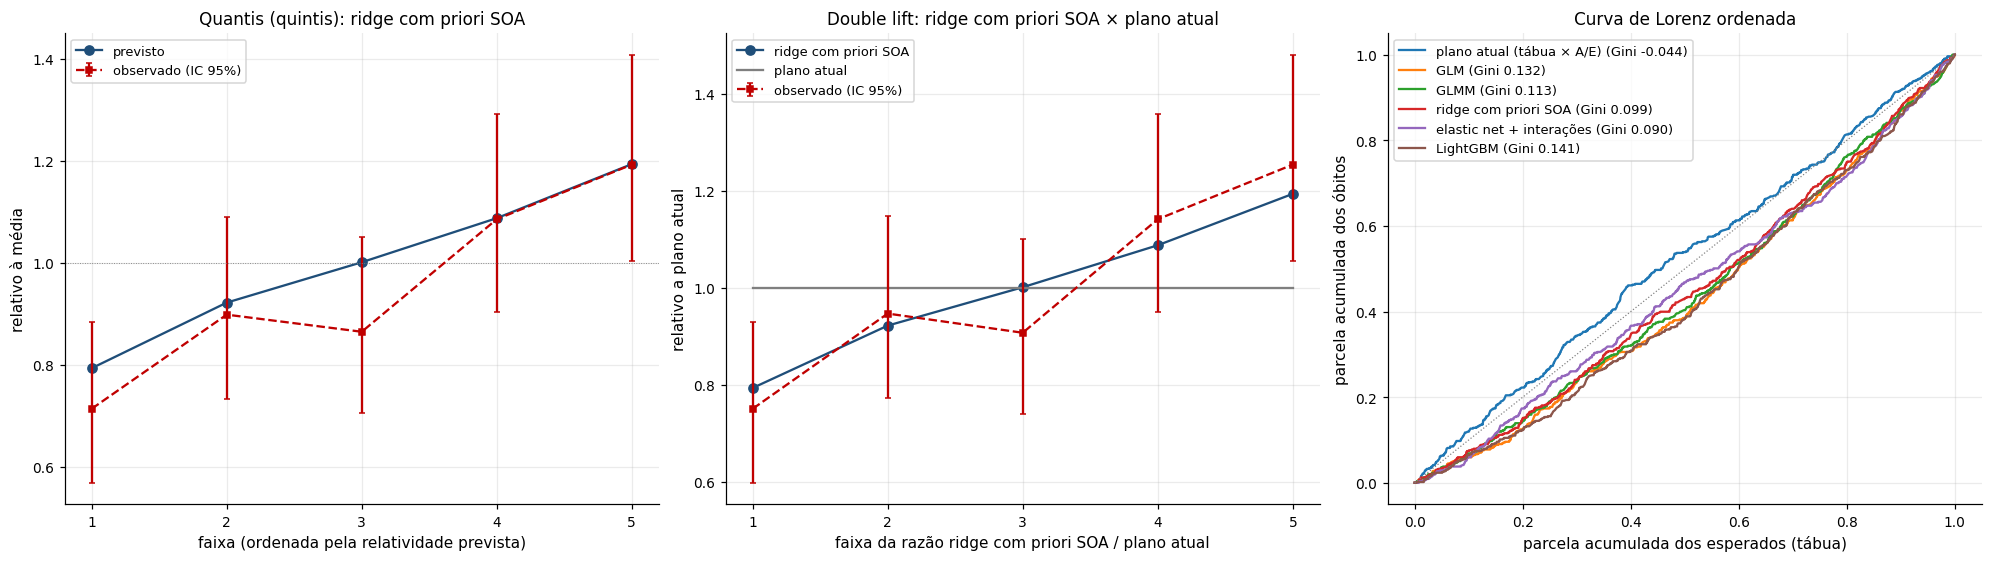

,variável,nível,N,mu_ridge,A/M,A/M inf,A/M sup,IC exclui 100%
0,faixa_capital,150-400k,70,78.3313,0.8936,0.6966,1.1291,False
1,faixa_capital,30-60k,193,208.8403,0.9242,0.7984,1.0641,False
2,faixa_capital,60-150k,169,167.7354,1.0075,0.8614,1.1714,False
3,faixa_capital,acima400k,16,12.4968,1.2803,0.7318,2.0792,False
4,faixa_capital,ate30k,105,114.0007,0.9210,0.7533,1.1150,False
0,cnae_secao,C,90,103.0435,0.8734,0.7023,1.0736,False
1,cnae_secao,F,62,58.9303,1.0521,0.8066,1.3487,False
2,cnae_secao,G,52,61.7273,0.8424,0.6292,1.1047,False
3,cnae_secao,H,99,87.9273,1.1259,0.9151,1.3708,False
4,cnae_secao,K,7,17.4125,0.4020,0.1616,0.8283,True


In [10]:
col = {'ridge com priori SOA': 'mu_ridge', 'GLMM': 'mu_glmm', 'GLM': 'mu_glm', 'plano atual (tábua × A/E)': 'mu_plano'}[escolhido]
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
A.grafico_quantis(ax[0], A.quantis(te, col, n=5), f"Quantis (quintis): {escolhido}")
A.grafico_double_lift(ax[1], A.double_lift(te, col, "mu_plano", n=5), escolhido, "plano atual")
A.grafico_lorenz(ax[2], {n: A.lorenz_gini(te, c) for n, c in PREV.items()})
plt.show()
am = pd.concat([A.tabela_am(te, v, col).rename(columns={v: "nível"}).assign(variável=v) for v in ["faixa_capital", "cnae_secao"]])
am[["variável", "nível", "N", col, "A/M", "A/M inf", "A/M sup", "IC exclui 100%"]]

Quintis em vez de decis: com ~500 óbitos, decis teriam ~50 óbitos cada e intervalos largos demais.

## 6. Reajuste com toda a experiência e tabela de fatores

In [11]:
tudo, itudo = base(None)
meta = {"gerado_em": pd.Timestamp.today().date().isoformat(), "fonte_dados": "carteira sintética",
        "tabua": tabua.nome, "tabua_sha256": tabua.sha256, "corte_experiencia": itudo["corte_experiencia"],
        "obitos": itudo["obitos"], "esperados_tabua": round(itudo["esperados"], 2),
        "teste_fora_do_tempo": f"{ite['inicio_experiencia']} a {ite['corte_experiencia']}",
        "anos_excluidos_experiencia": itudo["anos_excluidos"],
        "candidatos_empatados_no_teste": empatados, "secoes_agrupadas_em_OUTRAS": itudo["secoes_agrupadas_em_OUTRAS"]}
tabela = M.ajustar_tabela(tudo, escolhido, cm, prioris, meta)
M.salvar_tabela(tabela, RAIZ / "artefatos/fatores_manual.yaml")
print(f"Modelo: {escolhido} | A/E base: {tabela['ae_base']:.4f} | elasticidade ao capital: {tabela['capital']['elasticidade']:.4f}")
pd.Series(tabela["secao"]).sort_values().to_frame("fator de seção (base = 1)")

Modelo: ridge com priori SOA | A/E base: 1.1457 | elasticidade ao capital: -0.0962


,fator de seção (base = 1)
M,0.7312
P,0.7843
K,0.7933
Q,0.8013
J,0.8118
S,0.8791
G,0.9121
A,0.9131
N,0.9150
O,0.9360


## 7. Exemplo: taxa pura manual de um grupo

In [12]:
ref = pd.Timestamp(cfg["data_referencia"])
ativos = dados["vidas"][dados["vidas"]["data_fim"].isna()]
porte = ativos["id_estipulante"].value_counts()
grupo = porte.index[len(porte) // 2]
censo = ativos[ativos["id_estipulante"] == grupo]
e = dados["estipulantes"].set_index("id_estipulante").loc[grupo]
cot = M.taxa_pura_manual(censo, e["cnae_secao"], e["cnae_divisao"], tabela, tabua, ref + pd.Timedelta(days=1))
pd.Series({"estipulante": grupo, "atividade": f"{e['cnae_secao']}:{e['cnae_divisao']}", "vidas": cot["vidas"],
           "capital total (R$)": cot["capital_total"], "fator de atividade": cot["fator_atividade"],
           "prêmio puro anual (R$)": cot["premio_puro_anual"], "taxa pura mensal (‰)": cot["taxa_pura_mensal_mil"],
           "avisos": "; ".join(cot["avisos"]) or "nenhum"}).to_frame("cotação")

,cotação
estipulante,EST0013
atividade,G:46
vidas,466
capital total (R$),"89,493,700.0000"
fator de atividade,0.9121
prêmio puro anual (R$),"114,917.4888"
taxa pura mensal (‰),0.1070
avisos,divisão sem experiência ['G:46']: usada a médi...


## Limitações
- **Um ano de teste com ~500 óbitos** não separa os candidatos: a escolha vem da ordem de preferência fixada antes.
  Na base real, com mais volume, o mesmo procedimento pode separar.
- **Carteira sintética:** os números refletem as hipóteses do gerador; a verificação de que o código recupera a
  verdade está no notebook 90.
- **Priori:** forma americana (2010–2013), mapeada para CNAE por julgamento; o lambda decide quanto a carteira se
  afasta dela.